# Cuaderno 2 · Construir y entrenar una red: inicialización, lotes y ONNX

**Postgrado en Inteligencia Artificial para la Ingeniería Aeroespacial · Deep Learning con Keras · Sesión 3**

En el cuaderno 1 entrenamos redes con las opciones por defecto. Aquí abrimos la caja y experimentamos con las decisiones que hay detrás de `fit()`:

1. **Inicialización de los pesos**: por qué importa, el problema de la simetría, y Glorot frente a He.
2. **Batch, mini-batch y SGD**: cuántos ejemplos usar por paso, y qué cuesta cada opción.
3. **Tasa de aprendizaje y optimizadores**: η demasiado pequeña o grande, *schedules*, momentum y Adam.
4. **Guardar y exportar a ONNX**: llevar el modelo fuera de Python y comprobar que da lo mismo.

Usamos de nuevo el problema del **estado del turbofán** (14 sensores, 4 clases) con datos sintéticos generados en el propio cuaderno.

> Necesitarás `onnxruntime` y `tf2onnx` para la parte 4: `pip install onnxruntime tf2onnx`.

## 0 · Preparación

In [1]:
import os, time, logging, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"           # menos mensajes de TensorFlow
logging.getLogger("tensorflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import layers
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "· backend:", keras.backend.backend())

AZUL, NARANJA, GRIS, AZUL_OSC = "#0D6FCF", "#E8791E", "#6B6B6B", "#08447C"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

Keras 3.15.1 · backend: tensorflow


In [2]:
# Mismo generador de datos del turbofán que en el cuaderno 1
rng = np.random.default_rng(1)
sensores = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "Ps30", "phi", "NRf", "BPR", "W31"]
media  = np.array([518.7, 642.5, 1590, 1405, 14.6, 21.6, 553.5, 2388, 9065, 47.5, 521.6, 2388, 8.44, 38.9])
escala = np.array([0.01, 0.5, 6, 9, 0.01, 0.01, 0.9, 0.07, 22, 0.27, 0.74, 0.07, 0.04, 0.18])
clases = ["Normal", "Compresor", "Turbina", "Sensor"]

def generar_motor(n_por_clase=1500):
    X, y = [], []
    for c in range(4):
        Z = rng.normal(0, 1, (n_por_clase, 14))
        if c == 1: Z[:, [1, 2]] += 1.6; Z[:, 6] -= 1.4; Z[:, 9] += 1.2
        if c == 2: Z[:, 3] += 2.0; Z[:, 6] -= 0.8; Z[:, 13] -= 1.3
        if c == 3:
            idx = rng.integers(0, 14, n_por_clase)
            Z[np.arange(n_por_clase), idx] += rng.choice([-1, 1], n_por_clase) * rng.uniform(4, 7, n_por_clase)
        X.append(media + Z * escala); y.append(np.full(n_por_clase, c))
    return np.vstack(X).astype("float32"), np.concatenate(y)

X, y = generar_motor()
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=0)

norm = layers.Normalization()
norm.adapt(X_train)
print("entrenamiento:", X_train.shape, " validación:", X_val.shape, " prueba:", X_test.shape)

entrenamiento: (4199, 14)  validación: (901, 14)  prueba: (900, 14)


Una función auxiliar para construir el MLP con distintas opciones, y otra para dibujar curvas de varios experimentos a la vez.

In [3]:
def construir(ocultas=(32, 16), inicializador="glorot_uniform", activacion="relu"):
    # MLP para el turbofán: normalización + capas ocultas + softmax de 4 clases.
    capas = [keras.Input(shape=(14,)), norm]
    for u in ocultas:
        capas.append(layers.Dense(u, activation=activacion, kernel_initializer=inicializador))
    capas.append(layers.Dense(4, activation="softmax"))
    return keras.Sequential(capas)


def comparar(historias, clave="val_loss", titulo=None, eje_x=None, log=False):
    # Dibuja la misma métrica de varios entrenamientos. historias = {nombre: History}
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for (nombre, h), col in zip(historias.items(), [AZUL, NARANJA, GRIS, AZUL_OSC, "#2899F9"]):
        xs = eje_x[nombre] if eje_x else range(1, len(h.history[clave]) + 1)
        ax.plot(xs, h.history[clave], color=col, label=nombre, lw=2)
    ax.set_xlabel("segundos" if eje_x else "época"); ax.set_ylabel(clave)
    if log: ax.set_yscale("log")
    ax.set_title(titulo or clave); ax.legend(); plt.tight_layout(); plt.show()

---
## 1 · Inicialización de los pesos

### 1.1 · ¿Llega la señal viva a la última capa?

Reproducimos con Keras el experimento de la sesión 3: una red de **10 capas densas de 256 neuronas con ReLU**, sin entrenar, a la que pasamos datos aleatorios. Medimos la desviación típica de las activaciones en cada capa para cuatro inicializaciones.

Para leer las salidas intermedias construimos un segundo modelo cuyas salidas son las de todas las capas.

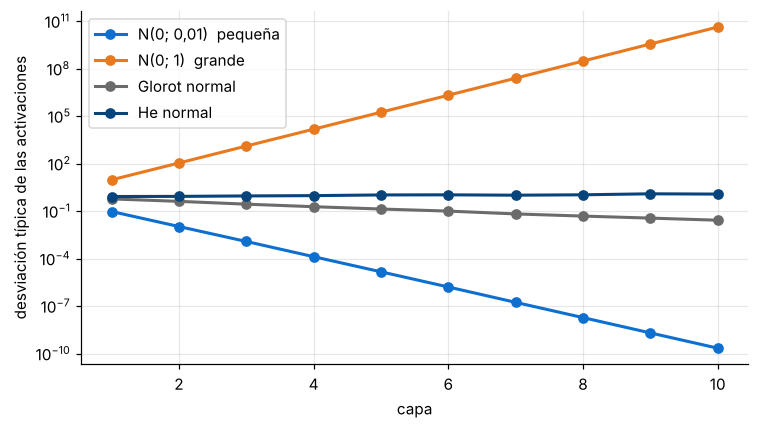

N(0; 0,01)  pequeña    capa 1:    0.0936   capa 10:  2.17e-10
N(0; 1)  grande        capa 1:      9.41   capa 10:  4.21e+10
Glorot normal          capa 1:     0.585   capa 10:    0.0264
He normal              capa 1:     0.829   capa 10:      1.18


In [4]:
x_rand = np.random.default_rng(0).normal(size=(1000, 256)).astype("float32")

inits = {
    "N(0; 0,01)  pequeña": keras.initializers.RandomNormal(stddev=0.01),
    "N(0; 1)  grande":     keras.initializers.RandomNormal(stddev=1.0),
    "Glorot normal":       "glorot_normal",
    "He normal":           "he_normal",
}

desv = {}
for nombre, ini in inits.items():
    entrada = keras.Input(shape=(256,))
    h, salidas = entrada, []
    for _ in range(10):
        h = layers.Dense(256, activation="relu", use_bias=False, kernel_initializer=ini)(h)
        salidas.append(h)
    sonda = keras.Model(entrada, salidas)            # devuelve las 10 activaciones
    desv[nombre] = [float(a.std()) for a in sonda.predict(x_rand, verbose=0)]

fig, ax = plt.subplots(figsize=(7, 4))
for (nombre, d), col in zip(desv.items(), [AZUL, NARANJA, GRIS, AZUL_OSC]):
    ax.semilogy(range(1, 11), d, "o-", color=col, label=nombre, lw=2)
ax.set_xlabel("capa"); ax.set_ylabel("desviación típica de las activaciones")
ax.legend(); plt.tight_layout(); plt.show()

for nombre, d in desv.items():
    print(f"{nombre:22s} capa 1: {d[0]:9.3g}   capa 10: {d[-1]:9.3g}")

- Con pesos **demasiado pequeños**, la señal se apaga: las últimas capas reciben prácticamente ceros y sus gradientes también se desvanecen.
- Con pesos **demasiado grandes**, la señal explota.
- **Glorot** está pensada para activaciones simétricas (tanh, sigmoide); con ReLU pierde algo de escala en cada capa.
- **He** compensa que ReLU anula la mitad de las entradas y mantiene la escala estable.

### 1.2 · El problema de la simetría

¿Y si inicializamos todos los pesos con **el mismo valor**? Todas las neuronas de una capa calculan lo mismo y reciben el mismo gradiente, así que **siguen siendo idénticas después de entrenar**: es como tener una sola neurona por capa.

In [5]:
keras.utils.set_random_seed(0)
modelo_cte = construir(inicializador=keras.initializers.Constant(0.05))
modelo_cte.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo_cte.fit(X_train, y_train, epochs=20, batch_size=64, verbose=0)

W1 = modelo_cte.layers[1].get_weights()[0]           # kernel de la primera Dense: (14, 32)
print("Forma del kernel:", W1.shape)
print("¿Son iguales las 32 neuronas (columnas)?", np.allclose(W1, W1[:, :1]))
print("Accuracy en validación:", round(modelo_cte.evaluate(X_val, y_val, verbose=0)[1], 3))

Forma del kernel: (14, 32)
¿Son iguales las 32 neuronas (columnas)? True
Accuracy en validación: 0.512


Las 32 neuronas siguen siendo copias exactas tras entrenar. El modelo aprende algo (gracias a la capa de salida), pero desperdicia toda la capacidad de las capas ocultas. Por eso los pesos se inicializan **al azar**. Los **sesgos** sí pueden empezar a cero: la aleatoriedad de los pesos ya rompe la simetría.

### 1.3 · Efecto sobre el entrenamiento de una red profunda

Entrenamos una red de **8 capas ocultas de 64 neuronas** con tres inicializaciones y comparamos la pérdida de validación.

N(0; 0,01)                 val_accuracy final: 0.250


Glorot uniforme (defecto)  val_accuracy final: 0.814


He normal                  val_accuracy final: 0.814


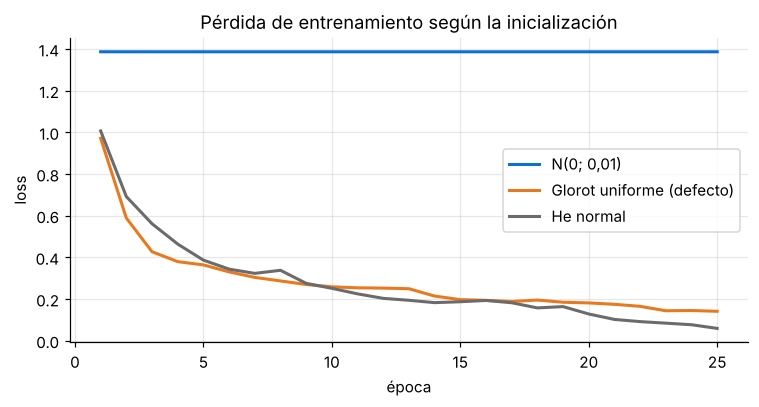

In [6]:
hist_init = {}
for nombre, ini in [("N(0; 0,01)", keras.initializers.RandomNormal(stddev=0.01)),
                    ("Glorot uniforme (defecto)", "glorot_uniform"),
                    ("He normal", "he_normal")]:
    keras.utils.set_random_seed(0)
    m = construir(ocultas=(64,) * 8, inicializador=ini)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist_init[nombre] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=25, batch_size=64, verbose=0)
    print(f"{nombre:26s} val_accuracy final: {hist_init[nombre].history['val_accuracy'][-1]:.3f}")

comparar(hist_init, "loss", "Pérdida de entrenamiento según la inicialización")

Con pesos muy pequeños la red se queda **atascada** en una pérdida de $\ln 4 \approx 1{,}386$, que es lo que vale la entropía cruzada cuando predice 1/4 para cada clase (no sabe nada): la señal y los gradientes se desvanecen antes de llegar a las primeras capas. Glorot y He arrancan enseguida.

(Mostramos la pérdida de **entrenamiento** para aislar el efecto de la inicialización. En validación, esta red de 8 capas acaba sobreajustando: lo trataremos en el cuaderno 3.)

> **En Keras**, `Dense` usa por defecto `kernel_initializer="glorot_uniform"` y `bias_initializer="zeros"`. Con ReLU, `he_normal` es una buena costumbre, aunque con redes poco profundas y Adam la diferencia suele ser pequeña.

---
## 2 · Batch, mini-batch y SGD

El argumento `batch_size` de `fit()` decide cuántos ejemplos se usan para calcular **cada** gradiente:

| Variante | `batch_size` | Actualizaciones por época (N = 4.199) |
|---|---|---|
| Batch | N | 1 |
| Estocástico (SGD puro) | 1 | 4.199 |
| Mini-batch | 64 | ⌈4.199 / 64⌉ = 66 |

Comparamos las tres con el **mismo optimizador** (SGD con η = 0,05) y medimos también el **tiempo de reloj**.

In [7]:
class Cronometro(keras.callbacks.Callback):
    # Guarda los segundos transcurridos al final de cada época.
    def on_train_begin(self, logs=None):
        self.t0, self.t = time.perf_counter(), []
    def on_epoch_end(self, epoch, logs=None):
        self.t.append(time.perf_counter() - self.t0)

N = len(X_train)
hist_bs, tiempos = {}, {}
for nombre, bs, epocas in [("Batch (N)", N, 60), ("SGD (1)", 1, 6), ("Mini-batch (64)", 64, 60)]:
    keras.utils.set_random_seed(0)
    m = construir(inicializador="he_normal")
    m.compile(optimizer=keras.optimizers.SGD(learning_rate=0.05), loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    crono = Cronometro()
    hist_bs[nombre] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epocas,
                            batch_size=bs, callbacks=[crono], verbose=0)
    tiempos[nombre] = crono.t
    pasos = epocas * int(np.ceil(N / bs))
    print(f"{nombre:16s} {epocas:3d} épocas · {pasos:6d} actualizaciones · {crono.t[-1]:5.1f} s · "
          f"val_accuracy {hist_bs[nombre].history['val_accuracy'][-1]:.3f}")

Batch (N)         60 épocas ·     60 actualizaciones ·   3.4 s · val_accuracy 0.600


SGD (1)            6 épocas ·  25194 actualizaciones ·  25.6 s · val_accuracy 0.800


Mini-batch (64)   60 épocas ·   3960 actualizaciones ·   8.6 s · val_accuracy 0.839


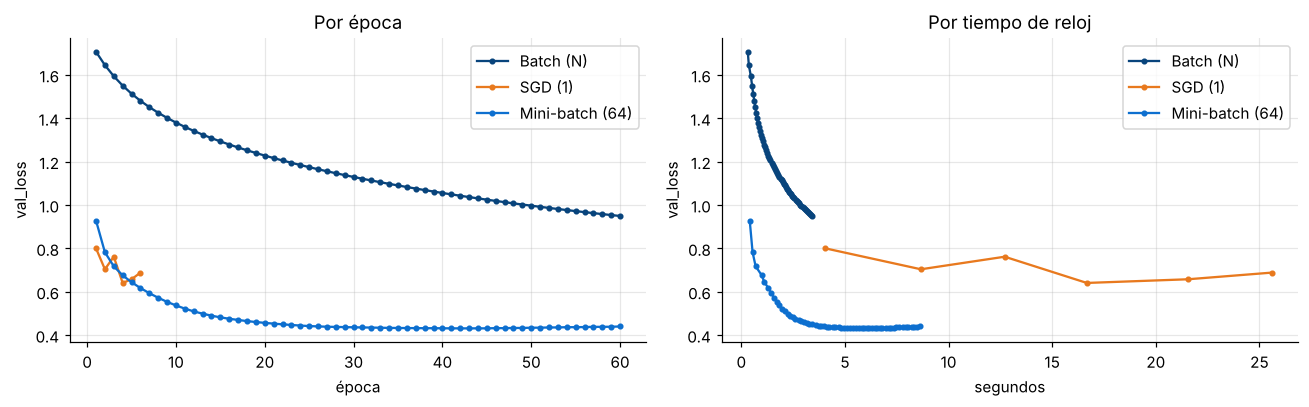

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (nombre, h), col in zip(hist_bs.items(), [AZUL_OSC, NARANJA, AZUL]):
    axes[0].plot(range(1, len(h.history["val_loss"]) + 1), h.history["val_loss"], "o-", ms=3, color=col, label=nombre)
    axes[1].plot(tiempos[nombre], h.history["val_loss"], "o-", ms=3, color=col, label=nombre)
axes[0].set_xlabel("época"); axes[1].set_xlabel("segundos")
for ax in axes: ax.set_ylabel("val_loss"); ax.legend()
axes[0].set_title("Por época"); axes[1].set_title("Por tiempo de reloj")
plt.tight_layout(); plt.show()

Lo que muestran las gráficas:

- **Batch**: cada época es muy rápida, pero solo da **un paso**. Tras 60 épocas apenas ha empezado a aprender.
- **SGD puro**: progresa mucho en cada época (4.199 pasos), pero cada época es **lenta** porque procesa los ejemplos de uno en uno, y la curva es más ruidosa.
- **Mini-batch**: el equilibrio. Muchas actualizaciones por época y buen aprovechamiento del hardware (operaciones vectorizadas).

Por eso el mini-batch es lo habitual, y en Keras el optimizador llamado `SGD` trabaja en la práctica con mini-lotes.

### 2.1 · ¿Influye el tamaño del mini-lote?

Con el número de épocas fijo, lotes más grandes dan **menos actualizaciones**. Si se agranda el lote, conviene revisar también la tasa de aprendizaje.

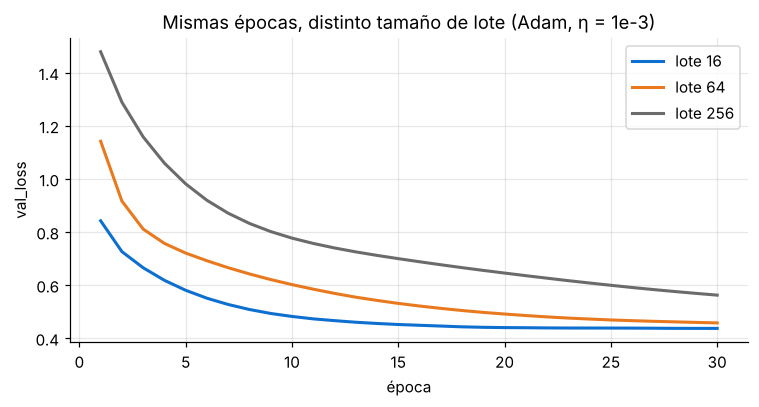

In [9]:
hist_mb = {}
for bs in [16, 64, 256]:
    keras.utils.set_random_seed(0)
    m = construir(inicializador="he_normal")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist_mb[f"lote {bs}"] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=bs, verbose=0)
comparar(hist_mb, "val_loss", "Mismas épocas, distinto tamaño de lote (Adam, η = 1e-3)")

---
## 3 · Tasa de aprendizaje y optimizadores

### 3.1 · η demasiado pequeña, adecuada y demasiado grande

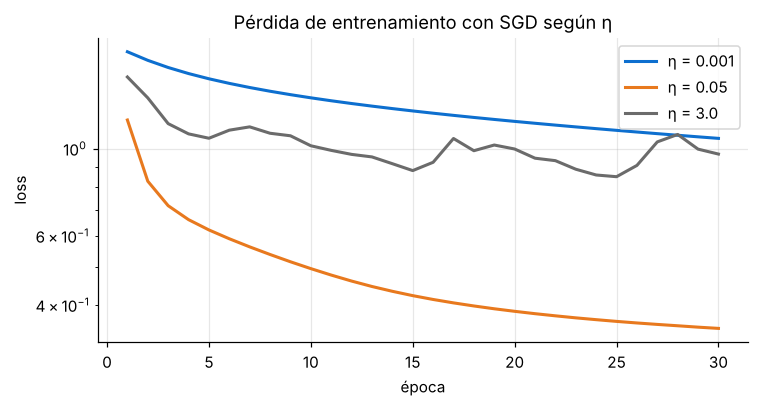

In [10]:
hist_lr = {}
for eta in [0.001, 0.05, 3.0]:
    keras.utils.set_random_seed(0)
    m = construir(inicializador="he_normal")
    m.compile(optimizer=keras.optimizers.SGD(learning_rate=eta), loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
    hist_lr[f"η = {eta}"] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, verbose=0)
comparar(hist_lr, "loss", "Pérdida de entrenamiento con SGD según η", log=True)

- η = 0,001: converge, pero **muy despacio**.
- η = 0,05: converge rápido y estable.
- η = 3: los pasos son tan grandes que la pérdida **oscila o diverge** (puede llegar a `nan`).

### 3.2 · SGD, SGD con momentum y Adam

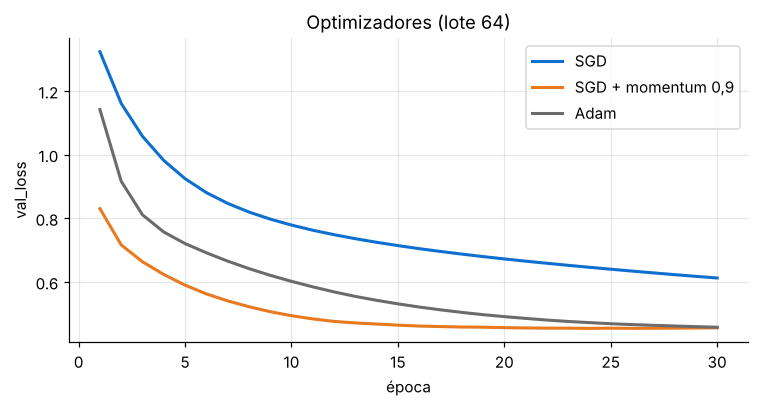

In [11]:
hist_opt = {}
for nombre, opt in [("SGD", keras.optimizers.SGD(0.01)),
                    ("SGD + momentum 0,9", keras.optimizers.SGD(0.01, momentum=0.9)),
                    ("Adam", keras.optimizers.Adam(1e-3))]:
    keras.utils.set_random_seed(0)
    m = construir(inicializador="he_normal")
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist_opt[nombre] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, verbose=0)
comparar(hist_opt, "val_loss", "Optimizadores (lote 64)")

El *momentum* acumula «inercia» en la dirección del gradiente y acelera mucho a SGD con la misma η. Adam, además, adapta la tasa de cada parámetro: por eso es una buena opción por defecto.

### 3.3 · Tasa de aprendizaje variable

Dos formas de reducir η durante el entrenamiento:

- un **schedule** fijo, como `CosineDecay`, que baja η siguiendo un coseno a lo largo de un número de **pasos** (lotes, no épocas);
- el *callback* `ReduceLROnPlateau`, que la divide cuando la pérdida de validación se estanca.

Registramos η en cada época con un pequeño *callback* para verlo.

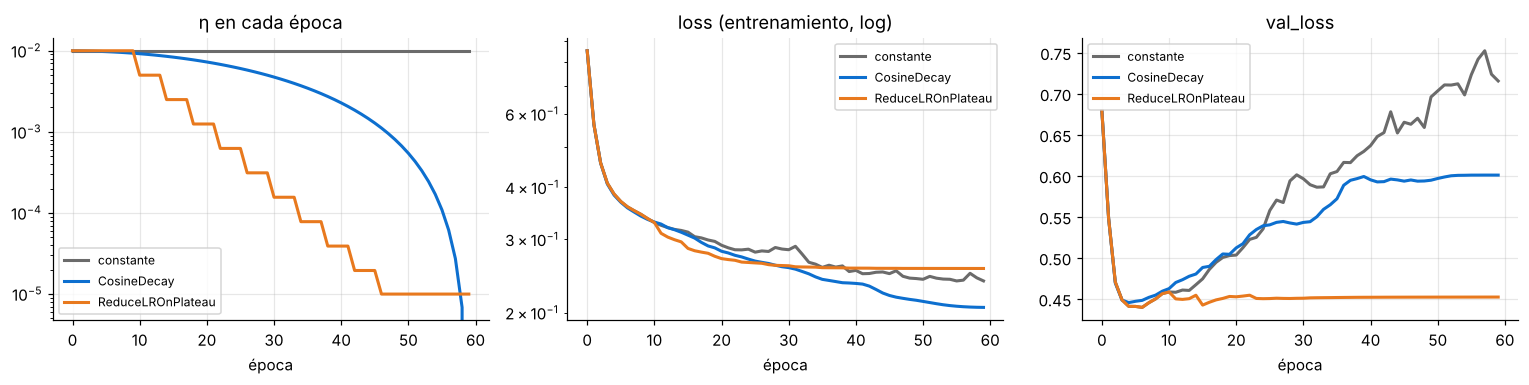

constante          loss final 0.238   val_loss mínima 0.440   val_loss final 0.715
CosineDecay        loss final 0.206   val_loss mínima 0.445   val_loss final 0.601
ReduceLROnPlateau  loss final 0.255   val_loss mínima 0.440   val_loss final 0.452


In [12]:
class RegistroLR(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.lr = []
    def on_epoch_end(self, epoch, logs=None):
        opt = self.model.optimizer
        self.lr.append(float(keras.ops.convert_to_numpy(opt.learning_rate)))

epocas, bs = 60, 64
pasos_totales = epocas * int(np.ceil(len(X_train) / bs))
experimentos = {
    "constante":          (keras.optimizers.Adam(1e-2), []),
    "CosineDecay":        (keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(1e-2, decay_steps=pasos_totales)), []),
    "ReduceLROnPlateau":  (keras.optimizers.Adam(1e-2), [keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)]),
}
hist_sched, lrs = {}, {}
for nombre, (opt, cbs) in experimentos.items():
    keras.utils.set_random_seed(0)
    m = construir(inicializador="he_normal")
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    reg = RegistroLR()
    hist_sched[nombre] = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epocas,
                               batch_size=bs, callbacks=cbs + [reg], verbose=0)
    lrs[nombre] = reg.lr

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for (nombre, h), col in zip(hist_sched.items(), [GRIS, AZUL, NARANJA]):
    axes[0].plot(lrs[nombre], color=col, lw=2, label=nombre)
    axes[1].plot(h.history["loss"], color=col, lw=2, label=nombre)
    axes[2].plot(h.history["val_loss"], color=col, lw=2, label=nombre)
axes[0].set_yscale("log"); axes[1].set_yscale("log")
axes[0].set_title("η en cada época"); axes[1].set_title("loss (entrenamiento, log)"); axes[2].set_title("val_loss")
for ax in axes: ax.set_xlabel("época"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for nombre, h in hist_sched.items():
    print(f"{nombre:18s} loss final {h.history['loss'][-1]:.3f}   val_loss mínima {min(h.history['val_loss']):.3f}"
          f"   val_loss final {h.history['val_loss'][-1]:.3f}")

Lo que se observa:

- Con **η = 0,01 constante** la red aprende rápido pero acaba **sobreajustando**: la pérdida de validación empieza a subir muy pronto.
- **CosineDecay** mantiene η alta casi hasta el final y luego la reduce: logra la **menor pérdida de entrenamiento** (afina mejor el mínimo), pero no evita el sobreajuste.
- **ReduceLROnPlateau** reacciona a la validación: baja η en cuanto se estanca y la pérdida de validación se queda cerca de su mínimo.

Reducir η ayuda a afinar. Para combatir el sobreajuste de forma directa necesitaremos otras herramientas (dropout, regularización, *early stopping*): cuaderno 3.

> **Ejercicios (partes 1 a 3)**
> 1. Repite el experimento 1.1 con `activation="tanh"`. ¿Cuál de las inicializaciones funciona mejor ahora?
> 2. En 1.2, cambia `Constant(0.05)` por `"zeros"`. ¿Aprende algo la red? ¿Por qué? (Pista: ¿cuánto vale la derivada de ReLU en 0?)
> 3. Con mini-batch de 256, prueba a multiplicar η por 4. ¿Recuperas la velocidad del lote de 64?
> 4. Encuentra la η más grande con la que SGD todavía converge en este problema.

---
## 4 · Guardar y exportar a ONNX

### 4.1 · El modelo final

Entrenamos el modelo definitivo con lo aprendido: inicialización He, Adam y mini-lotes de 64, y comprobamos su resultado en prueba (una sola vez).

In [13]:
keras.utils.set_random_seed(0)
modelo = construir(inicializador="he_normal")
modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=64, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
print("Accuracy en prueba:", round(modelo.evaluate(X_test, y_test, verbose=0)[1], 3))

Accuracy en prueba: 0.827


### 4.2 · Formato nativo `.keras` y solo pesos

In [14]:
import os

modelo.save("turbofan.keras")                       # arquitectura + pesos + optimizador
modelo.save_weights("turbofan.weights.h5")          # solo pesos

recargado = keras.models.load_model("turbofan.keras")
print("Predicciones idénticas:", np.allclose(recargado.predict(X_test[:50], verbose=0),
                                             modelo.predict(X_test[:50], verbose=0)))

# Solo pesos: hay que reconstruir la misma arquitectura en código antes de cargarlos
otro = construir(inicializador="he_normal")
otro.load_weights("turbofan.weights.h5")
print("Con load_weights también:", np.allclose(otro.predict(X_test[:50], verbose=0),
                                               modelo.predict(X_test[:50], verbose=0)))
for f in ["turbofan.keras", "turbofan.weights.h5"]:
    print(f"{f:22s} {os.path.getsize(f) / 1024:6.1f} KB")

Predicciones idénticas: True
Con load_weights también: True
turbofan.keras           41.1 KB
turbofan.weights.h5      38.0 KB


### 4.3 · Exportar a ONNX… y comprobar las entradas

En Keras 3 basta con `model.export(ruta, format="onnx")`. Pero **nunca hay que dar por buena una exportación sin inspeccionarla**. Veamos qué entradas espera el archivo resultante.

In [15]:
import onnxruntime as ort

modelo.export("turbofan_v0.onnx", format="onnx", verbose=False)
sesion = ort.InferenceSession("turbofan_v0.onnx", providers=["CPUExecutionProvider"])
for e in sesion.get_inputs():
    print(f"entrada: {e.name:45s} forma {e.shape}")

entrada: keras_tensor_157                              forma ['unk__8', 14]
entrada: sequential_19_1/normalization_1/Sub/y:0       forma [1, 14]
entrada: sequential_19_1/normalization_1/Sqrt/x:0      forma [1, 14]


**¡Sorpresa!** Según la versión de Keras, TensorFlow y tf2onnx, la media y la varianza de la capa `Normalization` pueden aparecer como **entradas adicionales** del grafo en lugar de constantes. Un programa en C++ que solo envíe los 14 sensores fallaría (o, peor, alguien podría «arreglarlo» enviando valores incorrectos).

Si en tu instalación solo aparece una entrada, ¡perfecto! Si aparecen tres, la solución es sencilla: antes de exportar, sustituimos `Normalization` por dos capas `Rescaling` (que calculan `x · scale + offset`) con la media y la desviación **como constantes**:

1. `Rescaling(scale=1, offset=-μ)` → $x - \mu$
2. `Rescaling(scale=1/σ)` → $(x - \mu)/\sigma$

¿Por qué no en una sola capa, $x \cdot \frac{1}{\sigma} - \frac{\mu}{\sigma}$? Es matemáticamente idéntico, pero con sensores como `T2` (media ≈ 518,7 y σ ≈ 0,01) se restan dos números del orden de 50.000 casi iguales en `float32` y se pierde precisión (*cancelación catastrófica*). Restar primero la media evita el problema.

In [16]:
mu = norm.mean.numpy().ravel()
sigma = np.sqrt(norm.variance.numpy().ravel())

modelo_export = keras.Sequential(
    [keras.Input(shape=(14,), name="sensores"),
     layers.Rescaling(scale=1.0, offset=-mu, name="restar_media"),
     layers.Rescaling(scale=1 / sigma, name="dividir_sigma")]
    + modelo.layers[1:],                              # reutilizamos las capas Dense ya entrenadas
    name="turbofan_export")

print("Mismas predicciones que el original:",
      np.allclose(modelo_export.predict(X_test, verbose=0), modelo.predict(X_test, verbose=0), atol=1e-5))

modelo_export.export("turbofan.onnx", format="onnx", verbose=False)
sesion = ort.InferenceSession("turbofan.onnx", providers=["CPUExecutionProvider"])
for e in sesion.get_inputs():
    print(f"entrada: {e.name:20s} forma {e.shape}   tipo {e.type}")
for s in sesion.get_outputs():
    print(f"salida:  {s.name:20s} forma {s.shape}")

Mismas predicciones que el original: True


entrada: sensores             forma ['unk__13', 14]   tipo tensor(float)
salida:  Identity:0           forma ['unk__14', 4]


Ahora el `.onnx` tiene **una sola entrada** de forma `(lote, 14)`: el primer eje es simbólico, así que admite cualquier tamaño de lote.

### 4.4 · Ejecutar con ONNX Runtime y verificar

Este bloque es lo que haría, por ejemplo, el software de un sistema embarcado: no usa Keras ni TensorFlow, solo `onnxruntime` (que también existe para C++, C#, Java…).

In [17]:
nombre_entrada = sesion.get_inputs()[0].name
p_onnx  = sesion.run(None, {nombre_entrada: X_test.astype(np.float32)})[0]
p_keras = modelo.predict(X_test, verbose=0)

print("Forma de la salida:", p_onnx.shape)
print("Diferencia máxima con Keras:", float(np.abs(p_onnx - p_keras).max()))
print("¿Equivalentes (atol 1e-5)?  ", np.allclose(p_onnx, p_keras, atol=1e-5))
print("¿Misma clase predicha?       ", bool((p_onnx.argmax(1) == p_keras.argmax(1)).all()))

Forma de la salida: (900, 4)
Diferencia máxima con Keras: 6.556510925292969e-07
¿Equivalentes (atol 1e-5)?   True
¿Misma clase predicha?        True


In [18]:
# Tiempo de inferencia de un único motor (caso típico en tiempo real).
# predict() está pensado para lotes grandes y tiene sobrecarga fija; para una muestra, modelo(x) es más ligero.
x1 = X_test[:1].astype(np.float32)
for nombre, f in [("Keras predict()", lambda: modelo.predict(x1, verbose=0)),
                  ("Keras modelo(x)", lambda: modelo(x1, training=False)),
                  ("ONNX Runtime",    lambda: sesion.run(None, {nombre_entrada: x1}))]:
    f()                                              # calentamiento
    t0 = time.perf_counter()
    for _ in range(200): f()
    print(f"{nombre:16s} {(time.perf_counter() - t0) / 200 * 1e3:7.3f} ms por muestra")
print(f"\nTamaño del archivo .onnx: {os.path.getsize('turbofan.onnx') / 1024:.1f} KB")

Keras predict()   41.014 ms por muestra


Keras modelo(x)    1.768 ms por muestra
ONNX Runtime       0.006 ms por muestra

Tamaño del archivo .onnx: 7.1 KB


> Para **ver el grafo** del modelo exportado puedes abrir `turbofan.onnx` en [Netron](https://netron.app).

### Lista de comprobación antes de desplegar un `.onnx`

1. ¿Tiene **solo las entradas que esperas**, con la forma y el tipo (`float32`) correctos?
2. ¿Incluye el **preprocesado** (normalización) o el sistema de destino debe aplicarlo?
3. ¿Coinciden sus salidas con las de Keras sobre **datos reales**?
4. ¿Has guardado junto al archivo la **versión** del modelo, los datos con los que se entrenó y el orden de los sensores?

> **Ejercicios (parte 4)**
> 1. Exporta el modelo de regresión del cuaderno 1 (`despegue.keras`) a ONNX y compara sus predicciones con Keras.
> 2. Abre `turbofan.onnx` en Netron e identifica las operaciones de cada capa (`MatMul`, `Add`, `Relu`, `Softmax`…).
> 3. Escribe el orden de los 14 sensores en un archivo JSON junto al `.onnx`. ¿Por qué es importante?